# 04 — Validation et explicabilité du modèle prédictif

## Modèle retenu

\[
M_{T1}: Profil + T0 + T1 \rightarrow T2
\]

Algorithme principal : **RandomForestRegressor**

Modèle secondaire : **DecisionTreeRegressor**

## Objectifs

Cette étape vise à :

1. confirmer les performances prédictives obtenues à l'étape 03 ;
2. analyser les erreurs de prédiction ;
3. vérifier la stabilité du modèle ;
4. identifier les variables contribuant le plus aux prédictions ;
5. expliquer globalement et localement les prédictions ;
6. préparer les résultats nécessaires à la recommandation pédagogique.

Les performances de référence restent celles obtenues par validation
croisée imbriquée dans l'étape 03. Le réentraînement sur l'ensemble
N=125 sert à construire et expliquer le modèle final, et non à
réestimer sa performance prédictive.

# Cellule 1 — Imports

In [1]:
# ============================================================
# CELLULE 1 — Imports
# ============================================================

from pathlib import Path

import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

from sklearn.model_selection import (
    KFold,
    GridSearchCV
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.inspection import permutation_importance

import joblib


RANDOM_STATE = 42

warnings.filterwarnings(
    "ignore",
    message=r"Found unknown categories in columns.*",
    category=UserWarning
)

print("✅ Imports chargés")

✅ Imports chargés


# Cellule 2 — Répertoires

In [2]:
# ============================================================
# CELLULE 2 — Répertoires
# ============================================================

def trouver_racine_projet():

    candidats = [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd().parent.parent
    ]

    for racine in candidats:

        if (
            racine
            / "outputs"
            / "03_modelisation_MT0_MT1"
        ).exists():

            return racine.resolve()

    raise FileNotFoundError(
        "outputs/03_modelisation_MT0_MT1 introuvable."
    )


PROJECT_ROOT = trouver_racine_projet()


INPUT_03 = (
    PROJECT_ROOT
    / "outputs"
    / "03_modelisation_MT0_MT1"
)


OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "04_validation_XAI"
)


FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
MODEL_DIR = OUTPUT_DIR / "models"


for dossier in [
    OUTPUT_DIR,
    FIGURE_DIR,
    TABLE_DIR,
    MODEL_DIR
]:

    dossier.mkdir(
        parents=True,
        exist_ok=True
    )


print("PROJECT_ROOT :", PROJECT_ROOT)
print("INPUT 03     :", INPUT_03)
print("OUTPUT 04    :", OUTPUT_DIR)

PROJECT_ROOT : /home/andrycomputer/Documents/Model-eval-pers-elearning
INPUT 03     : /home/andrycomputer/Documents/Model-eval-pers-elearning/outputs/03_modelisation_MT0_MT1
OUTPUT 04    : /home/andrycomputer/Documents/Model-eval-pers-elearning/outputs/04_validation_XAI


# Cellule 3 — Charger les résultats validés de l’étape 03

In [3]:
# ============================================================
# CELLULE 3 — Chargement des sorties 03
# ============================================================

BASE_125 = pd.read_csv(
    INPUT_03 / "base_modelisation_MT1_N125.csv"
)

BASE_105 = pd.read_csv(
    INPUT_03 / "base_modelisation_MT1_N105.csv"
)


OOF_MT1_105 = pd.read_csv(
    INPUT_03 / "oof_MT1_N105.csv"
)

OOF_MT1_125 = pd.read_csv(
    INPUT_03
    / "oof_MT1_N125_agrege.csv"
)

OOF_MT1_105 = pd.read_csv(
    INPUT_03
    / "oof_MT1_N105_agrege.csv"
)

RESULTATS_N125 = pd.read_csv(
    INPUT_03 / "resultats_nested_cv_N125.csv"
)


RESULTATS_N105 = pd.read_csv(
    INPUT_03 / "resultats_nested_cv_N105.csv"
)


PARAMS_MT1_125 = pd.read_csv(
    INPUT_03 / "parametres_MT1_N125.csv"
)


with open(
    INPUT_03 / "configuration_MT1.json",
    encoding="utf-8"
) as f:

    CONFIG = json.load(f)


FEATURES_MT1_NUM = CONFIG["FEATURES_MT1_NUM"]
FEATURES_MT1_CAT = CONFIG["FEATURES_MT1_CAT"]

FEATURES_MT1 = (
    FEATURES_MT1_NUM
    + FEATURES_MT1_CAT
)

TARGET = CONFIG["TARGET"]


print("Base principale :", BASE_125.shape)
print("Base sensibilité :", BASE_105.shape)

print(
    "Variables numériques :",
    len(FEATURES_MT1_NUM)
)

print(
    "Variables catégorielles :",
    len(FEATURES_MT1_CAT)
)

print(
    "Total prédicteurs :",
    len(FEATURES_MT1)
)

print(
    "Cible :",
    TARGET
)

print(
    "Modèle retenu :",
    CONFIG["MODELE_RETENU"]
)

Base principale : (125, 52)
Base sensibilité : (105, 52)
Variables numériques : 24
Variables catégorielles : 6
Total prédicteurs : 30
Cible : TARGET_T2
Modèle retenu : RandomForest


# Cellule 4 — Contrôle avant validation XAI

In [4]:
# ============================================================
# CELLULE 4 — Contrôles
# ============================================================

colonnes_manquantes = [
    c
    for c in FEATURES_MT1 + [TARGET]
    if c not in BASE_125.columns
]


print(
    "Colonnes manquantes :",
    colonnes_manquantes
)


assert len(colonnes_manquantes) == 0

assert len(BASE_125) == 125
assert len(BASE_105) == 105

assert BASE_125[TARGET].notna().all()
assert BASE_105[TARGET].notna().all()


X_125 = BASE_125[
    FEATURES_MT1
].copy()

y_125 = BASE_125[
    TARGET
].copy()


X_105 = BASE_105[
    FEATURES_MT1
].copy()

y_105 = BASE_105[
    TARGET
].copy()


print("\n✅ Données prêtes pour 04_validation_XAI")

print(
    "X_125 :",
    X_125.shape,
    "| y_125 :",
    y_125.shape
)

print(
    "X_105 :",
    X_105.shape,
    "| y_105 :",
    y_105.shape
)

Colonnes manquantes : []

✅ Données prêtes pour 04_validation_XAI
X_125 : (125, 30) | y_125 : (125,)
X_105 : (105, 30) | y_105 : (105,)


Phase A — Vérification des performances issues de 03
Phase B — Analyse détaillée des erreurs OOF
Phase C — Réentraînement final RandomForest sur N=125
Phase D — Importance des variables
Phase E — SHAP / explicabilité globale et locale
Phase F — Validation de stabilité et limites
Phase G — Exports vers 05_groupes_recommandation.ipynb

# Phase A — Validation du RandomForest retenu

# Cellule 5 — Extraire RandomForest et Dummy sur N=125 / N=105

In [5]:
# ============================================================
# CELLULE 5 — Validation des performances RandomForest
# ============================================================

def resume_modele(
    df,
    n_cohorte,
    modele
):

    temp = df[
        (df["FRAMEWORK"] == "M_T1")
        &
        (df["MODELE"] == modele)
    ].copy()


    assert len(temp) > 0, (
        f"{modele} absent"
    )


    return {
        "COHORTE":
            n_cohorte,

        "MODELE":
            modele,

        "N_EVALUATIONS":
            len(temp),

        "MAE_MOYEN":
            temp["MAE"].mean(),

        "MAE_STD":
            temp["MAE"].std(),

        "RMSE_MOYEN":
            temp["RMSE"].mean(),

        "RMSE_STD":
            temp["RMSE"].std(),

        "R2_MOYEN":
            temp["R2"].mean(),

        "R2_STD":
            temp["R2"].std()
    }


validation_A = pd.DataFrame([

    resume_modele(
        RESULTATS_N125,
        125,
        "RandomForest"
    ),

    resume_modele(
        RESULTATS_N125,
        125,
        "Dummy"
    ),

    resume_modele(
        RESULTATS_N105,
        105,
        "RandomForest"
    ),

    resume_modele(
        RESULTATS_N105,
        105,
        "Dummy"
    )

])


display(
    validation_A.round(4)
)

,COHORTE,MODELE,N_EVALUATIONS,MAE_MOYEN,MAE_STD,RMSE_MOYEN,RMSE_STD,R2_MOYEN,R2_STD
0,125,RandomForest,50,17.0670,1.5816,20.9286,2.0169,0.1619,0.2041
1,125,Dummy,50,20.3913,2.0960,24.8306,2.4118,-0.1637,0.1637
2,105,RandomForest,50,16.2194,2.2215,19.9953,2.7074,0.2333,0.1499
3,105,Dummy,50,19.7388,3.1392,24.2629,3.8940,-0.1075,0.1135


# Cellule 6 — Mesurer le gain par rapport au Dummy

In [6]:
# ============================================================
# CELLULE 6 — Gain RandomForest vs Dummy
# ============================================================

rf = validation_A[
    validation_A["MODELE"] == "RandomForest"
].set_index("COHORTE")

dummy = validation_A[
    validation_A["MODELE"] == "Dummy"
].set_index("COHORTE")


gain_vs_dummy = pd.DataFrame({

    "COHORTE": [125, 105],

    "GAIN_MAE": [
        dummy.loc[125, "MAE_MOYEN"]
        - rf.loc[125, "MAE_MOYEN"],

        dummy.loc[105, "MAE_MOYEN"]
        - rf.loc[105, "MAE_MOYEN"]
    ],

    "GAIN_RMSE": [
        dummy.loc[125, "RMSE_MOYEN"]
        - rf.loc[125, "RMSE_MOYEN"],

        dummy.loc[105, "RMSE_MOYEN"]
        - rf.loc[105, "RMSE_MOYEN"]
    ],

    "GAIN_R2": [
        rf.loc[125, "R2_MOYEN"]
        - dummy.loc[125, "R2_MOYEN"],

        rf.loc[105, "R2_MOYEN"]
        - dummy.loc[105, "R2_MOYEN"]
    ]
})


display(
    gain_vs_dummy.round(4)
)

,COHORTE,GAIN_MAE,GAIN_RMSE,GAIN_R2
0,125,3.3243,3.9020,0.3257
1,105,3.5194,4.2676,0.3408


# Cellule 7 — Vérifier la stabilité N=125 vs N=105

In [7]:
# ============================================================
# CELLULE 7 — Stabilité entre cohorte principale et sensibilité
# ============================================================

stabilite_rf = pd.DataFrame({

    "METRIQUE": [
        "MAE",
        "RMSE",
        "R2"
    ],

    "N125": [
        rf.loc[125, "MAE_MOYEN"],
        rf.loc[125, "RMSE_MOYEN"],
        rf.loc[125, "R2_MOYEN"]
    ],

    "N105": [
        rf.loc[105, "MAE_MOYEN"],
        rf.loc[105, "RMSE_MOYEN"],
        rf.loc[105, "R2_MOYEN"]
    ]
})


stabilite_rf["ECART_ABSOLU"] = abs(
    stabilite_rf["N125"]
    -
    stabilite_rf["N105"]
)


display(
    stabilite_rf.round(4)
)

,METRIQUE,N125,N105,ECART_ABSOLU
0,MAE,17.0670,16.2194,0.8477
1,RMSE,20.9286,19.9953,0.9333
2,R2,0.1619,0.2333,0.0713


# Cellule 8 — Validation automatique de la Phase A

In [8]:
# ============================================================
# CELLULE 8 — Validation automatique de la Phase A
# ============================================================

rf_125 = rf.loc[125]
rf_105 = rf.loc[105]

dummy_125 = dummy.loc[125]
dummy_105 = dummy.loc[105]


# ------------------------------------------------------------
# 1. Construire les contrôles
# ------------------------------------------------------------

validation_checks = pd.DataFrame(
    [
        {
            "COHORTE": 125,
            "METRIQUE": "MAE",
            "RF": rf_125["MAE_MOYEN"],
            "DUMMY": dummy_125["MAE_MOYEN"],
            "GAIN_RF": (
                dummy_125["MAE_MOYEN"]
                -
                rf_125["MAE_MOYEN"]
            )
        },

        {
            "COHORTE": 125,
            "METRIQUE": "RMSE",
            "RF": rf_125["RMSE_MOYEN"],
            "DUMMY": dummy_125["RMSE_MOYEN"],
            "GAIN_RF": (
                dummy_125["RMSE_MOYEN"]
                -
                rf_125["RMSE_MOYEN"]
            )
        },

        {
            "COHORTE": 125,
            "METRIQUE": "R2",
            "RF": rf_125["R2_MOYEN"],
            "DUMMY": dummy_125["R2_MOYEN"],
            "GAIN_RF": (
                rf_125["R2_MOYEN"]
                -
                dummy_125["R2_MOYEN"]
            )
        },

        {
            "COHORTE": 105,
            "METRIQUE": "MAE",
            "RF": rf_105["MAE_MOYEN"],
            "DUMMY": dummy_105["MAE_MOYEN"],
            "GAIN_RF": (
                dummy_105["MAE_MOYEN"]
                -
                rf_105["MAE_MOYEN"]
            )
        },

        {
            "COHORTE": 105,
            "METRIQUE": "RMSE",
            "RF": rf_105["RMSE_MOYEN"],
            "DUMMY": dummy_105["RMSE_MOYEN"],
            "GAIN_RF": (
                dummy_105["RMSE_MOYEN"]
                -
                rf_105["RMSE_MOYEN"]
            )
        },

        {
            "COHORTE": 105,
            "METRIQUE": "R2",
            "RF": rf_105["R2_MOYEN"],
            "DUMMY": dummy_105["R2_MOYEN"],
            "GAIN_RF": (
                rf_105["R2_MOYEN"]
                -
                dummy_105["R2_MOYEN"]
            )
        }
    ]
)


# ------------------------------------------------------------
# 2. Vérification de la validité numérique
# ------------------------------------------------------------

colonnes_numeriques = [
    "RF",
    "DUMMY",
    "GAIN_RF"
]


assert (
    np.isfinite(
        validation_checks[
            colonnes_numeriques
        ].to_numpy()
    )
    .all()
), (
    "Valeur non finie détectée "
    "dans les métriques de validation."
)


# ------------------------------------------------------------
# 3. Un gain positif signifie :
#
# MAE  : RF < Dummy
# RMSE : RF < Dummy
# R2   : RF > Dummy
# ------------------------------------------------------------

validation_checks[
    "VALIDE"
] = (
    validation_checks[
        "GAIN_RF"
    ] > 0
)


validation_checks[
    "CONTROLE"
] = (
    "RF_meilleur_Dummy_"
    +
    validation_checks[
        "METRIQUE"
    ]
    +
    "_N"
    +
    validation_checks[
        "COHORTE"
    ].astype(str)
)


validation_checks = (
    validation_checks[
        [
            "CONTROLE",
            "COHORTE",
            "METRIQUE",
            "RF",
            "DUMMY",
            "GAIN_RF",
            "VALIDE"
        ]
    ]
)


# ------------------------------------------------------------
# 4. Affichage complet
# ------------------------------------------------------------

print(
    "=== VALIDATION RANDOMFOREST vs DUMMY ==="
)


display(
    validation_checks.round(4)
)


# ------------------------------------------------------------
# 5. Identifier explicitement les contrôles échoués
# ------------------------------------------------------------

controles_echoues = (
    validation_checks[
        ~validation_checks[
            "VALIDE"
        ]
    ]
    .copy()
)


if len(
    controles_echoues
) > 0:

    print(
        "\nPhase A NON validée."
    )

    print(
        "Contrôles échoués :"
    )

    display(
        controles_echoues.round(4)
    )

    raise RuntimeError(
        "RandomForest M_T1 ne surpasse pas "
        "le Dummy sur tous les contrôles. "
        "Vérifier les sorties du Notebook 03 "
        "avant de poursuivre l'analyse XAI."
    )


# ------------------------------------------------------------
# 6. Conclusion
# ------------------------------------------------------------

print(
    "\nPhase A validée : "
    "RandomForest M_T1 surpasse le Dummy "
    "sur MAE, RMSE et R², "
    "pour N=125 et N=105."
)

=== VALIDATION RANDOMFOREST vs DUMMY ===


,CONTROLE,COHORTE,METRIQUE,RF,DUMMY,GAIN_RF,VALIDE
0,RF_meilleur_Dummy_MAE_N125,125,MAE,17.0670,20.3913,3.3243,True
1,RF_meilleur_Dummy_RMSE_N125,125,RMSE,20.9286,24.8306,3.9020,True
2,RF_meilleur_Dummy_R2_N125,125,R2,0.1619,-0.1637,0.3257,True
3,RF_meilleur_Dummy_MAE_N105,105,MAE,16.2194,19.7388,3.5194,True
4,RF_meilleur_Dummy_RMSE_N105,105,RMSE,19.9953,24.2629,4.2676,True
5,RF_meilleur_Dummy_R2_N105,105,R2,0.2333,-0.1075,0.3408,True



Phase A validée : RandomForest M_T1 surpasse le Dummy sur MAE, RMSE et R², pour N=125 et N=105.


# Cellule 9 — Export Phase A

In [9]:
# ============================================================
# CELLULE 9 — Export Phase A
# ============================================================

validation_A.to_csv(
    TABLE_DIR / "validation_performance_RF.csv",
    index=False,
    encoding="utf-8-sig"
)

gain_vs_dummy.to_csv(
    TABLE_DIR / "gain_RF_vs_Dummy.csv",
    index=False,
    encoding="utf-8-sig"
)

stabilite_rf.to_csv(
    TABLE_DIR / "stabilite_RF_N125_N105.csv",
    index=False,
    encoding="utf-8-sig"
)


print(
    "✅ Résultats Phase A exportés"
)

✅ Résultats Phase A exportés


# Phase B — analyse des erreurs OOF.

# Cellule 10 — Erreurs OOF RandomForest sur N=105

In [10]:
# ============================================================
# CELLULE 10 — Analyse des erreurs OOF RandomForest
# ============================================================

RF_OOF_105 = (
    OOF_MT1_105[
        OOF_MT1_105["MODELE"] == "RandomForest"
    ]
    .copy()
)


RF_OOF_105["ERREUR"] = (
    RF_OOF_105["Y_PRED"]
    - RF_OOF_105["Y_TRUE"]
)


RF_OOF_105["ERREUR_ABS"] = abs(
    RF_OOF_105["ERREUR"]
)


print("N =", len(RF_OOF_105))

print(
    "Biais moyen =",
    round(
        RF_OOF_105["ERREUR"].mean(),
        3
    )
)

print(
    "MAE OOF =",
    round(
        RF_OOF_105["ERREUR_ABS"].mean(),
        3
    )
)

print(
    "Erreur médiane =",
    round(
        RF_OOF_105["ERREUR_ABS"].median(),
        3
    )
)

N = 105
Biais moyen = -0.408
MAE OOF = 15.909
Erreur médiane = 13.39


# Cellule 11 — Taille des erreurs

In [11]:
# ============================================================
# CELLULE 11 — Distribution pratique des erreurs
# ============================================================

resume_erreurs = pd.DataFrame({

    "INDICATEUR": [
        "Erreur ≤ 5 points",
        "Erreur ≤ 10 points",
        "Erreur ≤ 15 points",
        "Erreur ≤ 20 points",
        "Erreur > 20 points"
    ],

    "POURCENTAGE": [

        (RF_OOF_105["ERREUR_ABS"] <= 5).mean() * 100,

        (RF_OOF_105["ERREUR_ABS"] <= 10).mean() * 100,

        (RF_OOF_105["ERREUR_ABS"] <= 15).mean() * 100,

        (RF_OOF_105["ERREUR_ABS"] <= 20).mean() * 100,

        (RF_OOF_105["ERREUR_ABS"] > 20).mean() * 100
    ]
})


display(
    resume_erreurs.round(2)
)

,INDICATEUR,POURCENTAGE
0,Erreur ≤ 5 points,19.05
1,Erreur ≤ 10 points,39.05
2,Erreur ≤ 15 points,55.24
3,Erreur ≤ 20 points,69.52
4,Erreur > 20 points,30.48


#  Cellule 12 — Plus grandes erreurs

In [12]:
# ============================================================
# CELLULE 12 — Cas les plus difficiles à prédire
# ============================================================

# ------------------------------------------------------------
# 1. Vérifications
# ------------------------------------------------------------

colonnes_requises = {
    "ROW_INDEX",
    "Y_TRUE",
    "Y_PRED",
    "ERREUR",
    "ABS_ERROR"
}


colonnes_manquantes = (
    colonnes_requises
    -
    set(
        RF_OOF_105.columns
    )
)


assert len(
    colonnes_manquantes
) == 0, (
    "Colonnes manquantes dans RF_OOF_105 : "
    f"{colonnes_manquantes}"
)


# ------------------------------------------------------------
# 2. Identifier les prédictions les plus difficiles
# ------------------------------------------------------------

plus_grandes_erreurs = (
    RF_OOF_105
    .sort_values(
        "ABS_ERROR",
        ascending=False
    )
    .head(15)
    .copy()
)


# ------------------------------------------------------------
# 3. Colonnes à afficher
# ------------------------------------------------------------

colonnes_affichage = [
    "ROW_INDEX",
    "Y_TRUE",
    "Y_PRED",
    "ERREUR",
    "ABS_ERROR"
]


# Ajouter l'incertitude entre répétitions si disponible
if (
    "Y_PRED_SD"
    in plus_grandes_erreurs.columns
):

    colonnes_affichage.append(
        "Y_PRED_SD"
    )


if (
    "N_PREDICTIONS"
    in plus_grandes_erreurs.columns
):

    colonnes_affichage.append(
        "N_PREDICTIONS"
    )


# ------------------------------------------------------------
# 4. Affichage
# ------------------------------------------------------------

display(
    plus_grandes_erreurs[
        colonnes_affichage
    ]
    .round(3)
)

,ROW_INDEX,Y_TRUE,Y_PRED,ERREUR,ABS_ERROR,Y_PRED_SD,N_PREDICTIONS
583,58,13.333,64.195,50.862,50.862,3.983,10
609,84,6.667,54.338,47.671,47.671,2.699,10
566,41,100.000,56.326,-43.674,43.674,4.626,10
527,2,100.000,58.369,-41.631,41.631,4.609,10
617,92,20.000,60.717,40.717,40.717,4.477,10
619,94,40.000,78.222,38.222,38.222,1.870,10
542,17,100.000,61.838,-38.162,38.162,3.386,10
625,100,93.333,57.421,-35.912,35.912,3.458,10
561,36,26.667,61.719,35.052,35.052,3.323,10
576,51,53.333,87.837,34.504,34.504,4.556,10


# Cellule 13 — Erreur selon le niveau réel de T2

In [13]:
# ============================================================
# CELLULE 13 — Erreur selon la zone du score T2
# ============================================================

RF_OOF_105["ZONE_T2"] = pd.cut(
    RF_OOF_105["Y_TRUE"],
    bins=[-np.inf, 40, 60, 80, np.inf],
    labels=[
        "T2 <= 40",
        "40 < T2 <= 60",
        "60 < T2 <= 80",
        "T2 > 80"
    ]
)


erreurs_par_zone = (
    RF_OOF_105
    .groupby(
        "ZONE_T2",
        observed=True
    )
    .agg(
        N=("Y_TRUE", "size"),
        SCORE_T2_MOYEN=("Y_TRUE", "mean"),
        PREDICTION_MOYENNE=("Y_PRED", "mean"),
        BIAIS_MOYEN=("ERREUR", "mean"),
        MAE=("ERREUR_ABS", "mean"),
        MEDIANE_ERREUR_ABS=("ERREUR_ABS", "median")
    )
    .reset_index()
)


display(
    erreurs_par_zone.round(3)
)

,ZONE_T2,N,SCORE_T2_MOYEN,PREDICTION_MOYENNE,BIAIS_MOYEN,MAE,MEDIANE_ERREUR_ABS
0,T2 <= 40,13,30.769,62.085,31.316,31.316,32.851
1,40 < T2 <= 60,25,53.600,66.526,12.926,13.001,9.727
2,60 < T2 <= 80,21,76.825,72.546,-4.279,11.387,11.994
3,T2 > 80,46,95.217,80.364,-14.853,15.200,12.320


# Cellule 14 — Sous-estimation / surestimation

In [14]:
# ============================================================
# CELLULE 14 — Sens des erreurs
# ============================================================

RF_OOF_105["TYPE_ERREUR"] = np.select(
    [
        RF_OOF_105["ERREUR"] < -5,
        RF_OOF_105["ERREUR"] > 5
    ],
    [
        "Sous-estimation > 5 pts",
        "Surestimation > 5 pts"
    ],
    default="Erreur <= 5 pts"
)


sens_erreurs = (
    RF_OOF_105["TYPE_ERREUR"]
    .value_counts()
    .rename_axis("TYPE_ERREUR")
    .reset_index(name="N")
)


sens_erreurs["POURCENTAGE"] = (
    sens_erreurs["N"]
    / len(RF_OOF_105)
    * 100
)


display(
    sens_erreurs.round(2)
)

,TYPE_ERREUR,N,POURCENTAGE
0,Sous-estimation > 5 pts,49,46.67
1,Surestimation > 5 pts,36,34.29
2,Erreur <= 5 pts,20,19.05


#  Cellule 15 — Export Phase B

In [15]:
# ============================================================
# CELLULE 15 — Export Phase B
# ============================================================

RF_OOF_105.to_csv(
    TABLE_DIR / "erreurs_OOF_RF_N105.csv",
    index=False,
    encoding="utf-8-sig"
)

resume_erreurs.to_csv(
    TABLE_DIR / "resume_erreurs_RF_N105.csv",
    index=False,
    encoding="utf-8-sig"
)

plus_grandes_erreurs.to_csv(
    TABLE_DIR / "plus_grandes_erreurs_RF_N105.csv",
    index=False,
    encoding="utf-8-sig"
)

erreurs_par_zone.to_csv(
    TABLE_DIR / "erreurs_RF_par_zone_T2.csv",
    index=False,
    encoding="utf-8-sig"
)

sens_erreurs.to_csv(
    TABLE_DIR / "sens_erreurs_RF_N105.csv",
    index=False,
    encoding="utf-8-sig"
)

print("✅ Phase B exportée")

✅ Phase B exportée


# Phase C = réentraîner le modèle final M_T1 + RandomForest sur les 125 apprenants,

# Cellule 16 — Préprocesseur final

In [16]:
# ============================================================
# CELLULE 16 — Préprocesseur final
# ============================================================

def creer_onehot():

    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            drop="first",
            sparse_output=False
        )

    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            drop="first",
            sparse=False
        )


def creer_preprocesseur(
    variables_num,
    variables_cat
):

    pipeline_num = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ])


    pipeline_cat = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            creer_onehot()
        )
    ])


    return ColumnTransformer([
        (
            "num",
            pipeline_num,
            variables_num
        ),
        (
            "cat",
            pipeline_cat,
            variables_cat
        )
    ])


print("✅ Préprocesseur défini")

✅ Préprocesseur défini


# Cellule 17 — Pipeline RandomForest final
On reprend la famille d'hyperparamètres utilisée dans l'étape 03.

In [17]:
# ============================================================
# CELLULE 17 — Pipeline final RandomForest
# ============================================================

preprocessor_final = creer_preprocesseur(
    FEATURES_MT1_NUM,
    FEATURES_MT1_CAT
)


pipeline_rf_final = Pipeline([

    (
        "preprocess",
        preprocessor_final
    ),

    (
        "model",
        RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )

])


PARAM_GRID_RF_FINAL = {

    "model__n_estimators":
        [200, 400],

    "model__max_depth":
        [3, 5, None],

    "model__min_samples_leaf":
        [2, 5],

    "model__max_features":
        ["sqrt", 1.0]

}


print("✅ Pipeline RandomForest final construit")

✅ Pipeline RandomForest final construit


#  Cellule 18 — Recherche des hyperparamètres finaux

In [18]:

import os
import warnings

# 1) Processus principal
warnings.filterwarnings(
    "ignore",
    message=r"Found unknown categories in columns.*",
    category=UserWarning,
)

# 2) Processus parallèles (joblib/loky) : hérité par les workers
os.environ["PYTHONWARNINGS"] = (
    "ignore:Found unknown categories in columns:UserWarning"
)

# 3) Redémarre les workers déjà lancés pour qu'ils prennent le filtre
from joblib.externals.loky import get_reusable_executor
get_reusable_executor().shutdown(wait=True)

# ============================================================
# CELLULE 18 — Tuning final sur N=125
# ============================================================

cv_final = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


recherche_rf_final = GridSearchCV(

    estimator=pipeline_rf_final,

    param_grid=PARAM_GRID_RF_FINAL,

    scoring="neg_mean_absolute_error",

    cv=cv_final,

    n_jobs=-1,

    refit=True,

    return_train_score=True
)


recherche_rf_final.fit(
    X_125,
    y_125
)


MODELE_RF_FINAL = (
    recherche_rf_final.best_estimator_
)


print("✅ RandomForest final entraîné")

print(
    "\nMeilleurs paramètres :"
)

for cle, valeur in (
    recherche_rf_final
    .best_params_
    .items()
):

    print(
        f"{cle} = {valeur}"
    )


print(
    "\nMAE CV interne :",
    round(
        -recherche_rf_final.best_score_,
        3
    )
)

✅ RandomForest final entraîné

Meilleurs paramètres :
model__max_depth = None
model__max_features = 1.0
model__min_samples_leaf = 5
model__n_estimators = 200

MAE CV interne : 16.472


#  Cellule 19 — Vérifier le modèle final

In [19]:
# ============================================================
# CELLULE 19 — Contrôle du modèle final
# ============================================================

rf_final = (
    MODELE_RF_FINAL
    .named_steps["model"]
)


controle_modele_final = pd.DataFrame({

    "PARAMETRE": [
        "n_estimators",
        "max_depth",
        "min_samples_leaf",
        "max_features"
    ],

    "VALEUR": [
        rf_final.n_estimators,
        rf_final.max_depth,
        rf_final.min_samples_leaf,
        rf_final.max_features
    ]

})


display(
    controle_modele_final
)


print(
    "\nNombre d'apprenants utilisés :",
    len(X_125)
)

print(
    "Nombre de prédicteurs initiaux :",
    X_125.shape[1]
)

,PARAMETRE,VALEUR
0,n_estimators,200.0
1,max_depth,NaN
2,min_samples_leaf,5.0
3,max_features,1.0



Nombre d'apprenants utilisés : 125
Nombre de prédicteurs initiaux : 30


# Cellule 20 — Sauvegarder le modèle final
Très important : on sauvegarde tout le pipeline, pas uniquement RandomForest.

In [20]:
# ============================================================
# CELLULE 20 — Sauvegarde du modèle final
# ============================================================

CHEMIN_MODELE_FINAL = (
    MODEL_DIR
    / "MT1_RandomForest_final.joblib"
)


joblib.dump(
    MODELE_RF_FINAL,
    CHEMIN_MODELE_FINAL
)


print(
    "✅ Modèle sauvegardé :",
    CHEMIN_MODELE_FINAL
)

✅ Modèle sauvegardé : /home/andrycomputer/Documents/Model-eval-pers-elearning/outputs/04_validation_XAI/models/MT1_RandomForest_final.joblib


# Cellule 21 — Sauvegarder sa configuration

In [21]:
# ============================================================
# CELLULE 21 — Métadonnées du modèle final
# ============================================================

# ------------------------------------------------------------
# 1. Récupérer automatiquement les performances de référence
#    issues de la validation du RandomForest sur N=125
# ------------------------------------------------------------

perf_rf_125 = (
    validation_A[
        (validation_A["COHORTE"] == 125)
        &
        (validation_A["MODELE"] == "RandomForest")
    ]
    .copy()
)


assert len(perf_rf_125) == 1, (
    "La ligne RandomForest / N=125 est absente "
    "ou présente plusieurs fois dans validation_A."
)


perf_rf_125 = perf_rf_125.iloc[0]


# ------------------------------------------------------------
# 2. Construire les métadonnées
# ------------------------------------------------------------

metadata_modele = {

    "framework":
        "M_T1",

    "formule":
        "Profil + T0 + T1 -> T2",

    "algorithme":
        "RandomForestRegressor",

    "n_apprenants_final":
        125,

    "n_features_initiales":
        len(FEATURES_MT1),

    "target":
        TARGET,

    "selection_metric":
        "MAE",

    "best_params":
        recherche_rf_final.best_params_,

    "performance_reference_nested_cv": {

        "MAE":
            float(
                perf_rf_125[
                    "MAE_MOYEN"
                ]
            ),

        "RMSE":
            float(
                perf_rf_125[
                    "RMSE_MOYEN"
                ]
            ),

        "R2":
            float(
                perf_rf_125[
                    "R2_MOYEN"
                ]
            )
    }
}


# ------------------------------------------------------------
# 3. Sauvegarder les métadonnées
# ------------------------------------------------------------

with open(
    MODEL_DIR
    / "MT1_RandomForest_final_metadata.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata_modele,
        f,
        ensure_ascii=False,
        indent=4
    )


# ------------------------------------------------------------
# 4. Vérification
# ------------------------------------------------------------

print("✅ Métadonnées sauvegardées")

print(
    "\nPerformance de référence utilisée :"
)

print(
    "MAE =",
    round(
        metadata_modele[
            "performance_reference_nested_cv"
        ]["MAE"],
        4
    )
)

print(
    "RMSE =",
    round(
        metadata_modele[
            "performance_reference_nested_cv"
        ]["RMSE"],
        4
    )
)

print(
    "R² =",
    round(
        metadata_modele[
            "performance_reference_nested_cv"
        ]["R2"],
        4
    )
)

✅ Métadonnées sauvegardées

Performance de référence utilisée :
MAE = 17.067
RMSE = 20.9286
R² = 0.1619


M_T1
Profil + T0 + T1 → T2
          ↓
RandomForest final
          ↓
entraîné sur N=125
          ↓
pipeline complet sauvegardé

# Phase D — Importance des variables.

# Cellule 22 — Importance native du RandomForest

In [22]:
# ============================================================
# CELLULE 22 — Importance native des variables transformées
# ============================================================

preprocessor_fitted = (
    MODELE_RF_FINAL
    .named_steps["preprocess"]
)

rf_fitted = (
    MODELE_RF_FINAL
    .named_steps["model"]
)


feature_names = (
    preprocessor_fitted
    .get_feature_names_out()
)


importance_rf = pd.DataFrame({

    "FEATURE_TRANSFORMEE":
        feature_names,

    "IMPORTANCE":
        rf_fitted.feature_importances_

})


importance_rf = (
    importance_rf
    .sort_values(
        "IMPORTANCE",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    importance_rf.head(20)
)

,FEATURE_TRANSFORMEE,IMPORTANCE
0,num__T1__SCORE,0.393164
1,num__P__DISPONIBILITE__En_semaine_Soir,0.062923
2,num__T0__S_DS,0.057068
3,cat__P__Objectif pro_Entrepreneur,0.045750
4,num__T0__S_IA,0.036239
5,num__P__NIVEAU_POWER_BI,0.035299
6,num__T0__S_BI,0.035102
7,num__P__AGE_2026,0.029400
8,num__P__NIVEAU_INFORMATIQUE,0.027963
9,num__P__MOTIVATION__Curiosite,0.026864


# Cellule 23 — Regrouper les One-Hot par variable originale

In [23]:
# ============================================================
# CELLULE 23 — Importance par variable originale
# ============================================================

def retrouver_variable_originale(
    feature_transformee
):

    # Numériques
    if feature_transformee.startswith("num__"):

        return feature_transformee.replace(
            "num__",
            "",
            1
        )

    # Catégorielles One-Hot
    if feature_transformee.startswith("cat__"):

        nom = feature_transformee.replace(
            "cat__",
            "",
            1
        )

        # On cherche d'abord les noms les plus longs
        # pour éviter les mauvaises correspondances
        for col in sorted(
            FEATURES_MT1_CAT,
            key=len,
            reverse=True
        ):

            if (
                nom == col
                or
                nom.startswith(col + "_")
            ):

                return col

    return feature_transformee


importance_rf[
    "VARIABLE_ORIGINALE"
] = (
    importance_rf[
        "FEATURE_TRANSFORMEE"
    ]
    .apply(
        retrouver_variable_originale
    )
)


importance_variables = (
    importance_rf

    .groupby(
        "VARIABLE_ORIGINALE",
        as_index=False
    )

    .agg(
        IMPORTANCE=("IMPORTANCE", "sum")
    )

    .sort_values(
        "IMPORTANCE",
        ascending=False
    )

    .reset_index(drop=True)
)


importance_variables[
    "IMPORTANCE_PCT"
] = (
    importance_variables["IMPORTANCE"]
    * 100
)


display(
    importance_variables.head(20)
)

,VARIABLE_ORIGINALE,IMPORTANCE,IMPORTANCE_PCT
0,T1__SCORE,0.393164,39.316399
1,P__DISPONIBILITE__En_semaine_Soir,0.062923,6.292272
2,P__Objectif pro,0.058364,5.836356
3,T0__S_DS,0.057068,5.706807
4,P__Niveau d'étude,0.045067,4.506674
5,T0__S_IA,0.036239,3.623864
6,P__NIVEAU_POWER_BI,0.035299,3.529891
7,T0__S_BI,0.035102,3.510218
8,P__AGE_2026,0.029400,2.940014
9,P__NIVEAU_INFORMATIQUE,0.027963,2.796293


# Cellule 24 — Permutation importance en validation croisée


In [24]:
# ============================================================
# CELLULE 24 — Permutation importance avec tuning interne
# ============================================================

from sklearn.base import clone


cv_xai = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


permutation_folds = []


for fold, (
    train_idx,
    test_idx
) in enumerate(
    cv_xai.split(
        X_125
    ),
    start=1
):

    X_train = X_125.iloc[
        train_idx
    ].copy()

    X_test = X_125.iloc[
        test_idx
    ].copy()

    y_train = y_125.iloc[
        train_idx
    ].copy()

    y_test = y_125.iloc[
        test_idx
    ].copy()


    inner_cv = KFold(
        n_splits=4,
        shuffle=True,
        random_state=
            RANDOM_STATE + fold
    )


    recherche_fold = GridSearchCV(

        estimator=clone(
            pipeline_rf_final
        ),

        param_grid=
            PARAM_GRID_RF_FINAL,

        scoring=
            "neg_mean_absolute_error",

        cv=inner_cv,

        n_jobs=-1,

        refit=True
    )


    recherche_fold.fit(
        X_train,
        y_train
    )


    modele_fold = (
        recherche_fold
        .best_estimator_
    )


    perm = permutation_importance(

        modele_fold,

        X_test,
        y_test,

        scoring=
            "neg_mean_absolute_error",

        n_repeats=30,

        random_state=
            RANDOM_STATE + fold,

        n_jobs=-1
    )


    for (
        feature,
        moyenne,
        std
    ) in zip(
        FEATURES_MT1,
        perm.importances_mean,
        perm.importances_std
    ):

        permutation_folds.append({
            "FOLD":
                fold,

            "VARIABLE":
                feature,

            "IMPORTANCE_MAE":
                moyenne,

            "IMPORTANCE_STD":
                std
        })


PERMUTATION_CV = pd.DataFrame(
    permutation_folds
)

# Cellule 25 — Graphique des 15 variables principales

In [25]:
# ============================================================
# CELLULE 25 — Visualisation permutation importance
# ============================================================

# ------------------------------------------------------------
# 1. Vérifier que la cellule 24 a bien été exécutée
# ------------------------------------------------------------

assert "PERMUTATION_CV" in globals(), (
    "PERMUTATION_CV n'existe pas. "
    "Exécute d'abord la Cellule 24."
)


# ------------------------------------------------------------
# 2. Construire le résumé si nécessaire
# ------------------------------------------------------------

permutation_resume = (

    PERMUTATION_CV

    .groupby(
        "VARIABLE",
        as_index=False
    )

    .agg(

        IMPORTANCE_MOYENNE=(
            "IMPORTANCE_MAE",
            "mean"
        ),

        IMPORTANCE_STD_FOLDS=(
            "IMPORTANCE_MAE",
            "std"
        ),

        IMPORTANCE_MEDIANE=(
            "IMPORTANCE_MAE",
            "median"
        )

    )

    .sort_values(
        "IMPORTANCE_MOYENNE",
        ascending=False
    )

    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. Sélection des 15 variables principales
# ------------------------------------------------------------

top15 = (
    permutation_resume
    .head(15)
    .sort_values(
        "IMPORTANCE_MOYENNE",
        ascending=True
    )
)


# ------------------------------------------------------------
# 4. Visualisation
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 7)
)


plt.barh(
    top15["VARIABLE"],
    top15["IMPORTANCE_MOYENNE"]
)


plt.xlabel(
    "Augmentation moyenne du MAE après permutation"
)


plt.ylabel(
    "Variable"
)


plt.title(
    "Importance globale des variables — RandomForest M_T1"
)


plt.tight_layout()


plt.savefig(
    FIGURE_DIR
    / "permutation_importance_RF_MT1.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()


# ------------------------------------------------------------
# 5. Tableau de contrôle
# ------------------------------------------------------------

display(
    permutation_resume.head(15)
)

<Figure size 900x700 with 1 Axes>

,VARIABLE,IMPORTANCE_MOYENNE,IMPORTANCE_STD_FOLDS,IMPORTANCE_MEDIANE
0,T1__SCORE,4.889516,0.972035,4.553230e+00
1,P__Objectif pro,0.470850,0.164703,4.394599e-01
2,P__DISPONIBILITE__En_semaine_Soir,0.381082,0.276961,5.587369e-01
3,T0__S_BI,0.237062,0.283001,8.565749e-02
4,P__MOTIVATION__Curiosite,0.184622,0.138668,2.117791e-01
5,T0__S_DS,0.139178,0.221805,1.792267e-01
6,P__NIVEAU_POWER_BI,0.136419,0.136606,9.418155e-02
7,T0__S_IA,0.125510,0.320412,2.348634e-01
8,P__NIVEAU_INFORMATIQUE,0.063518,0.074575,8.591731e-02
9,P__Filière,0.057390,0.101690,5.518897e-02


# Phase E — SHAP : explicabilité globale et individuelle.

# cellule 26 — Vérifier SHAP

In [26]:
# ============================================================
# CELLULE 26 — Vérification SHAP
# ============================================================

try:
    import shap

    print(
        "✅ SHAP disponible :",
        shap.__version__
    )

except ImportError:

    print(
        "❌ SHAP non installé"
    )
    print(
        "Installer avec : %pip install shap"
    )

✅ SHAP disponible : 0.46.0


#  Cellule 27 — Transformer les données avec le pipeline final

In [27]:
# ============================================================
# CELLULE 27 — Données transformées pour SHAP
# ============================================================

X_125_transforme = (
    preprocessor_fitted
    .transform(
        X_125
    )
)


feature_names_shap = (
    preprocessor_fitted
    .get_feature_names_out()
)


X_SHAP = pd.DataFrame(
    X_125_transforme,
    columns=feature_names_shap,
    index=X_125.index
)


print(
    "X_SHAP :",
    X_SHAP.shape
)

display(
    X_SHAP.head()
)

X_SHAP : (125, 61)


,num__P__AGE_2026,num__P__NIVEAU_INFORMATIQUE,num__P__NIVEAU_EXCEL,num__P__NIVEAU_POWER_BI,num__P__NIVEAU_PYTHON,num__P__NIVEAU_IA,num__P__MOTIVATION__Acquerir_des_competences_techniques,num__P__MOTIVATION__Ameliorer_mon_employabilite,num__P__MOTIVATION__Certification,num__P__MOTIVATION__Curiosite,...,cat__P__Statut actuel_Etudiant(e) en alternance,cat__P__Statut actuel_Etudiant(e) en fin d etudes,cat__P__Statut actuel_Etudiant(e) en stage,cat__P__Statut actuel_Professionnel(le) en activite,cat__P__Objectif pro_Consultant,cat__P__Objectif pro_Data Analyst,cat__P__Objectif pro_Data Scientist,cat__P__Objectif pro_Developpeur Python / IA,cat__P__Objectif pro_Entrepreneur,cat__P__Objectif pro_Non defini
0,0.396513,-2.887969,-2.114771,-0.743441,-0.927107,-1.792843,0.5,1.288245,-0.698638,-0.802955,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.108350,0.454588,-0.531859,-0.743441,1.736994,-0.298807,0.5,-0.776250,1.431356,1.245400,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-0.179814,0.454588,1.051054,0.603373,1.736994,-0.298807,0.5,-0.776250,1.431356,-0.802955,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.684677,0.454588,1.051054,0.603373,1.736994,-0.298807,0.5,-0.776250,1.431356,1.245400,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.396513,0.454588,1.051054,-0.743441,0.404943,1.195229,0.5,1.288245,1.431356,-0.802955,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


# Cellule 28 — Calcul SHAP

In [28]:
# ============================================================
# CELLULE 28 — Calcul des valeurs SHAP
# ============================================================

explainer = shap.TreeExplainer(
    rf_fitted
)


shap_values = explainer(
    X_SHAP
)


print(
    "✅ SHAP calculé"
)

print(
    "Shape :",
    shap_values.values.shape
)

✅ SHAP calculé
Shape : (125, 61)


# Cellule 29 — Importance SHAP globale

In [29]:
# ============================================================
# CELLULE 29 — Importance SHAP globale
# ============================================================

importance_shap = pd.DataFrame({

    "FEATURE_TRANSFORMEE":
        X_SHAP.columns,

    "MEAN_ABS_SHAP":
        np.abs(
            shap_values.values
        ).mean(axis=0)

})


importance_shap = (
    importance_shap
    .sort_values(
        "MEAN_ABS_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    importance_shap.head(20)
)

,FEATURE_TRANSFORMEE,MEAN_ABS_SHAP
0,num__T1__SCORE,10.793340
1,num__P__DISPONIBILITE__En_semaine_Soir,2.174049
2,cat__P__Objectif pro_Entrepreneur,1.317278
3,num__T0__S_DS,1.211780
4,num__P__NIVEAU_POWER_BI,1.179665
5,num__P__MOTIVATION__Curiosite,0.931073
6,num__P__DISPONIBILITE__Week_end,0.858855
7,num__P__NIVEAU_INFORMATIQUE,0.778081
8,num__T0__S_IA,0.746033
9,num__T0__S_BI,0.723024


# Cellule 30 — Graphique SHAP global

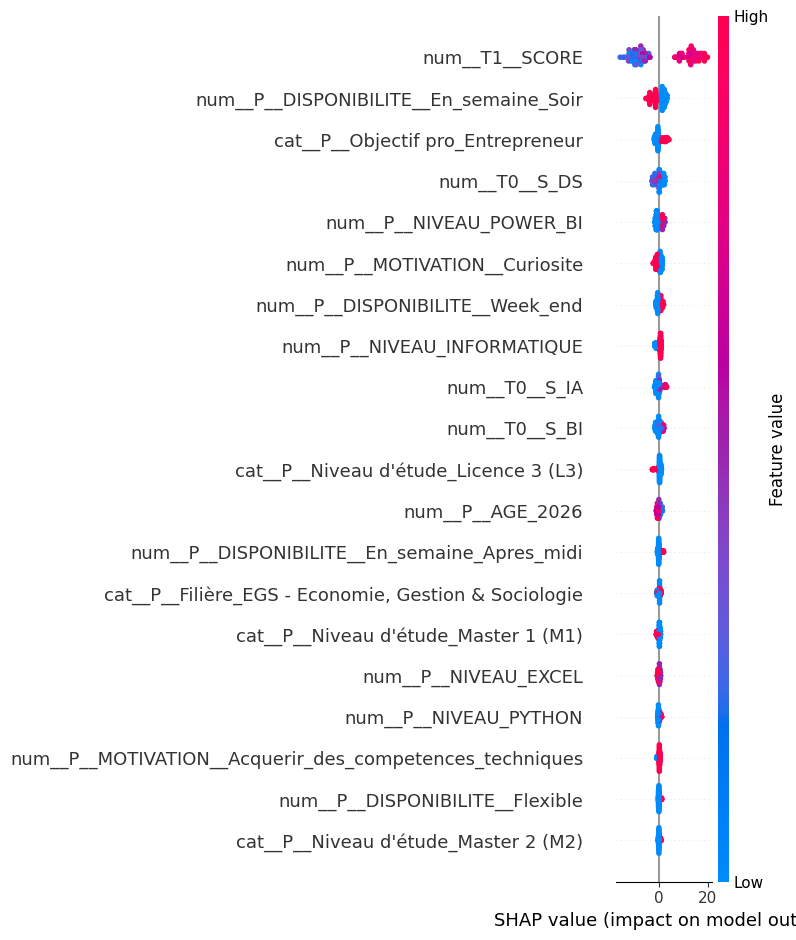

In [30]:
# ============================================================
# CELLULE 30 — SHAP summary plot
# ============================================================

shap.summary_plot(
    shap_values.values,
    X_SHAP,
    max_display=20,
    show=False
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "shap_summary_RF_MT1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Cellule 31 — Regrouper SHAP par variable originale

In [31]:
# ============================================================
# CELLULE 31 — SHAP regroupé par variable originale
# ============================================================

importance_shap[
    "VARIABLE_ORIGINALE"
] = (
    importance_shap[
        "FEATURE_TRANSFORMEE"
    ]
    .apply(
        retrouver_variable_originale
    )
)


importance_shap_original = (
    importance_shap
    .groupby(
        "VARIABLE_ORIGINALE",
        as_index=False
    )
    .agg(
        MEAN_ABS_SHAP=(
            "MEAN_ABS_SHAP",
            "sum"
        )
    )
    .sort_values(
        "MEAN_ABS_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    importance_shap_original.head(20)
)

,VARIABLE_ORIGINALE,MEAN_ABS_SHAP
0,T1__SCORE,10.793340
1,P__DISPONIBILITE__En_semaine_Soir,2.174049
2,P__Objectif pro,1.562618
3,P__Niveau d'étude,1.300557
4,T0__S_DS,1.211780
5,P__NIVEAU_POWER_BI,1.179665
6,P__MOTIVATION__Curiosite,0.931073
7,P__DISPONIBILITE__Week_end,0.858855
8,P__NIVEAU_INFORMATIQUE,0.778081
9,T0__S_IA,0.746033


# Cellule 32 — Explication locale d’un apprenant

In [32]:
# ============================================================
# CELLULE 32 — Fonction d'explication locale SHAP
# ============================================================

def expliquer_apprenant_shap(
    row_position,
    top_n=10
):

    valeurs = shap_values.values[
        row_position
    ]

    base_value = float(
        np.asarray(
            shap_values.base_values[
                row_position
            ]
        ).reshape(-1)[0]
    )

    prediction = float(
        MODELE_RF_FINAL.predict(
            X_125.iloc[
                [row_position]
            ]
        )[0]
    )

    score_reel = float(
        y_125.iloc[
            row_position
        ]
    )


    explication = pd.DataFrame({

        "VARIABLE":
            X_SHAP.columns,

        "VALEUR_SHAP":
            valeurs,

        "ABS_SHAP":
            np.abs(
                valeurs
            )

    })


    explication = (
        explication
        .sort_values(
            "ABS_SHAP",
            ascending=False
        )
        .head(top_n)
        .reset_index(drop=True)
    )


    print(
        "Position :",
        row_position
    )

    print(
        "Valeur de base :",
        round(
            base_value,
            3
        )
    )

    print(
        "Prédiction T2 :",
        round(
            prediction,
            3
        )
    )

    print(
        "T2 réel :",
        round(
            score_reel,
            3
        )
    )

    print(
        "Erreur :",
        round(
            prediction
            -
            score_reel,
            3
        )
    )


    display(
        explication
    )


    return explication

# Testez par exemple :

In [33]:
explication_0 = expliquer_apprenant_shap(
    row_position=0,
    top_n=10
)

Position : 0
Valeur de base : 72.192
Prédiction T2 : 80.218
T2 réel : 93.333
Erreur : -13.115


,VARIABLE,VALEUR_SHAP,ABS_SHAP
0,num__T1__SCORE,10.195364,10.195364
1,num__T0__S_IA,-1.374704,1.374704
2,num__T0__S_BI,-1.315968,1.315968
3,num__P__DISPONIBILITE__En_semaine_Soir,1.242889,1.242889
4,num__P__NIVEAU_INFORMATIQUE,-1.116723,1.116723
5,num__P__NIVEAU_POWER_BI,-0.905870,0.905870
6,cat__P__Niveau d'étude_Licence 3 (L3),0.728770,0.728770
7,num__P__DISPONIBILITE__Week_end,-0.641726,0.641726
8,cat__P__Objectif pro_Entrepreneur,0.572379,0.572379
9,num__P__AGE_2026,-0.454075,0.454075


# Cellule 33 — Choisir trois apprenants représentatifs

In [34]:
# ============================================================
# CELLULE 33 — Trois cas représentatifs
# ============================================================

positions_representatives = {

    "T2_FAIBLE":
        int(
            np.argmin(
                np.abs(
                    y_125.to_numpy() - 30
                )
            )
        ),

    "T2_INTERMEDIAIRE":
        int(
            np.argmin(
                np.abs(
                    y_125.to_numpy() - 60
                )
            )
        ),

    "T2_ELEVE":
        int(
            np.argmin(
                np.abs(
                    y_125.to_numpy() - 90
                )
            )
        )
}


print(
    positions_representatives
)

{'T2_FAIBLE': 14, 'T2_INTERMEDIAIRE': 6, 'T2_ELEVE': 0}


# Cellule 34 — Explications SHAP des trois cas

In [35]:
# ============================================================
# CELLULE 34 — Explications locales représentatives
# ============================================================

EXPLICATIONS_LOCALES = {}


for nom_cas, position in (
    positions_representatives.items()
):

    print(
        "\n",
        "=" * 70
    )

    print(
        nom_cas
    )

    print(
        "=" * 70
    )

    EXPLICATIONS_LOCALES[nom_cas] = (
        expliquer_apprenant_shap(
            row_position=position,
            top_n=10
        )
    )


T2_FAIBLE
Position : 14
Valeur de base : 72.192
Prédiction T2 : 45.512
T2 réel : 33.333
Erreur : 12.179


,VARIABLE,VALEUR_SHAP,ABS_SHAP
0,num__T1__SCORE,-9.551766,9.551766
1,num__P__DISPONIBILITE__En_semaine_Soir,-3.903467,3.903467
2,num__T0__S_DS,-2.970343,2.970343
3,num__P__NIVEAU_INFORMATIQUE,-1.649081,1.649081
4,cat__P__Objectif pro_Entrepreneur,-1.646621,1.646621
5,num__P__MOTIVATION__Curiosite,-1.410327,1.410327
6,num__P__AGE_2026,-0.958761,0.958761
7,num__P__NIVEAU_POWER_BI,-0.916055,0.916055
8,num__P__DISPONIBILITE__Week_end,-0.898266,0.898266
9,cat__P__Niveau d'étude_Master 1 (M1),-0.869258,0.869258



T2_INTERMEDIAIRE
Position : 6
Valeur de base : 72.192
Prédiction T2 : 64.862
T2 réel : 60.0
Erreur : 4.862


,VARIABLE,VALEUR_SHAP,ABS_SHAP
0,num__T1__SCORE,-7.311947,7.311947
1,cat__P__Objectif pro_Entrepreneur,2.829343,2.829343
2,num__P__DISPONIBILITE__En_semaine_Soir,2.217900,2.217900
3,num__P__MOTIVATION__Curiosite,-2.214489,2.214489
4,num__P__NIVEAU_POWER_BI,-1.785183,1.785183
5,num__T0__S_DS,1.270890,1.270890
6,"cat__P__Filière_EGS - Economie, Gestion & Soci...",-1.032979,1.032979
7,num__P__DISPONIBILITE__Week_end,0.757192,0.757192
8,cat__P__Genre_Masculin,-0.586519,0.586519
9,cat__P__Niveau d'étude_Licence 3 (L3),-0.541000,0.541000



T2_ELEVE
Position : 0
Valeur de base : 72.192
Prédiction T2 : 80.218
T2 réel : 93.333
Erreur : -13.115


,VARIABLE,VALEUR_SHAP,ABS_SHAP
0,num__T1__SCORE,10.195364,10.195364
1,num__T0__S_IA,-1.374704,1.374704
2,num__T0__S_BI,-1.315968,1.315968
3,num__P__DISPONIBILITE__En_semaine_Soir,1.242889,1.242889
4,num__P__NIVEAU_INFORMATIQUE,-1.116723,1.116723
5,num__P__NIVEAU_POWER_BI,-0.905870,0.905870
6,cat__P__Niveau d'étude_Licence 3 (L3),0.728770,0.728770
7,num__P__DISPONIBILITE__Week_end,-0.641726,0.641726
8,cat__P__Objectif pro_Entrepreneur,0.572379,0.572379
9,num__P__AGE_2026,-0.454075,0.454075


# Cellule 35 — Stabilité des variables importantes

On vérifie dans combien de folds chaque variable a une permutation importance positive.

In [36]:
# ============================================================
# CELLULE 35 — Stabilité des variables entre folds
# ============================================================

stabilite_variables = (
    PERMUTATION_CV
    .groupby(
        "VARIABLE",
        as_index=False
    )
    .agg(
        IMPORTANCE_MOYENNE=(
            "IMPORTANCE_MAE",
            "mean"
        ),
        IMPORTANCE_STD=(
            "IMPORTANCE_MAE",
            "std"
        ),
        NB_FOLDS_POSITIFS=(
            "IMPORTANCE_MAE",
            lambda x: (x > 0).sum()
        )
    )
)


stabilite_variables[
    "PCT_FOLDS_POSITIFS"
] = (
    stabilite_variables[
        "NB_FOLDS_POSITIFS"
    ] / PERMUTATION_CV["FOLD"].nunique() * 100
)


stabilite_variables = (
    stabilite_variables
    .sort_values(
        "IMPORTANCE_MOYENNE",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    stabilite_variables.head(20)
)

,VARIABLE,IMPORTANCE_MOYENNE,IMPORTANCE_STD,NB_FOLDS_POSITIFS,PCT_FOLDS_POSITIFS
0,T1__SCORE,4.889516,0.972035,5,100.0
1,P__Objectif pro,0.470850,0.164703,5,100.0
2,P__DISPONIBILITE__En_semaine_Soir,0.381082,0.276961,4,80.0
3,T0__S_BI,0.237062,0.283001,5,100.0
4,P__MOTIVATION__Curiosite,0.184622,0.138668,4,80.0
5,T0__S_DS,0.139178,0.221805,4,80.0
6,P__NIVEAU_POWER_BI,0.136419,0.136606,4,80.0
7,T0__S_IA,0.125510,0.320412,3,60.0
8,P__NIVEAU_INFORMATIQUE,0.063518,0.074575,4,80.0
9,P__Filière,0.057390,0.101690,4,80.0


Une variable présente dans 5/5 folds est plus crédible qu’une variable importante dans un seul fold.

# Cellule 36 — Comparaison des trois méthodes XAI
On compare :
- importance native RandomForest ;
- permutation importance ;
- SHAP.

In [37]:
# ============================================================
# CELLULE 36 — Synthèse XAI
# ============================================================

xai_synthese = (
    importance_variables[
        [
            "VARIABLE_ORIGINALE",
            "IMPORTANCE_PCT"
        ]
    ]
    .rename(
        columns={
            "VARIABLE_ORIGINALE":
                "VARIABLE",
            "IMPORTANCE_PCT":
                "RF_IMPORTANCE_PCT"
        }
    )
    .merge(
        permutation_resume[
            [
                "VARIABLE",
                "IMPORTANCE_MOYENNE"
            ]
        ],
        on="VARIABLE",
        how="outer"
    )
    .merge(
        importance_shap_original[
            [
                "VARIABLE_ORIGINALE",
                "MEAN_ABS_SHAP"
            ]
        ].rename(
            columns={
                "VARIABLE_ORIGINALE":
                    "VARIABLE"
            }
        ),
        on="VARIABLE",
        how="outer"
    )
)


xai_synthese = (
    xai_synthese
    .sort_values(
        "MEAN_ABS_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


display(
    xai_synthese.head(20)
)

,VARIABLE,RF_IMPORTANCE_PCT,IMPORTANCE_MOYENNE,MEAN_ABS_SHAP
0,T1__SCORE,39.316399,4.889516,10.793340
1,P__DISPONIBILITE__En_semaine_Soir,6.292272,0.381082,2.174049
2,P__Objectif pro,5.836356,0.470850,1.562618
3,P__Niveau d'étude,4.506674,-0.033288,1.300557
4,T0__S_DS,5.706807,0.139178,1.211780
5,P__NIVEAU_POWER_BI,3.529891,0.136419,1.179665
6,P__MOTIVATION__Curiosite,2.686388,0.184622,0.931073
7,P__DISPONIBILITE__Week_end,2.527143,-0.004271,0.858855
8,P__NIVEAU_INFORMATIQUE,2.796293,0.063518,0.778081
9,T0__S_IA,3.623864,0.125510,0.746033


Le résultat important attendu est que T1__SCORE soit dominant avec les trois méthodes.

# Cellule 37 — Synthèse finale du modèle

In [38]:
rf125 = validation_A[
    (validation_A["COHORTE"] == 125)
    &
    (validation_A["MODELE"] == "RandomForest")
].iloc[0]


rf105 = validation_A[
    (validation_A["COHORTE"] == 105)
    &
    (validation_A["MODELE"] == "RandomForest")
].iloc[0]


RF_OOF_105 = (
    OOF_MT1_105[
        OOF_MT1_105[
            "MODELE"
        ] == "RandomForest"
    ]
)


synthese_modele = pd.DataFrame({

    "ELEMENT": [
        "Framework",
        "Algorithme",
        "Population principale",
        "MAE repeated nested CV",
        "RMSE repeated nested CV",
        "R2 repeated nested CV",
        "MAE sensibilité N105",
        "R2 sensibilité N105",
        "Biais moyen OOF N105",
        "Variable XAI dominante",
        "Usage recommandé"
    ],

    "VALEUR": [
        "M_T1 : Profil + T0 + T1 -> T2",
        "RandomForestRegressor",
        "N=125",

        float(
            rf125["MAE_MOYEN"]
        ),

        float(
            rf125["RMSE_MOYEN"]
        ),

        float(
            rf125["R2_MOYEN"]
        ),

        float(
            rf105["MAE_MOYEN"]
        ),

        float(
            rf105["R2_MOYEN"]
        ),

        float(
            RF_OOF_105[
                "ERREUR"
            ].mean()
        ),

        "T1__SCORE",

        "Aide à la décision pédagogique"
    ]
})


display(synthese_modele)

,ELEMENT,VALEUR
0,Framework,M_T1 : Profil + T0 + T1 -> T2
1,Algorithme,RandomForestRegressor
2,Population principale,N=125
3,MAE repeated nested CV,17.067001
4,RMSE repeated nested CV,20.928635
5,R2 repeated nested CV,0.161927
6,MAE sensibilité N105,16.21935
7,R2 sensibilité N105,0.23325
8,Biais moyen OOF N105,-0.408263
9,Variable XAI dominante,T1__SCORE


Phase G — Exports
# Cellule 38 — Export de tous les résultats XAI

In [39]:
# ============================================================
# CELLULE 38 — Exports finaux du notebook 04
# ============================================================

exports_04 = {

    "importance_native_RF.csv":
        importance_variables,

    "permutation_importance_CV.csv":
        permutation_resume,

    "stabilite_variables_CV.csv":
        stabilite_variables,

    "importance_SHAP.csv":
        importance_shap_original,

    "synthese_XAI.csv":
        xai_synthese,

    "synthese_modele_final.csv":
        synthese_modele,

    "erreurs_OOF_RF_N105.csv":
        RF_OOF_105,

    "erreurs_par_zone_T2.csv":
        erreurs_par_zone,

    "sens_erreurs.csv":
        sens_erreurs
}


for nom, df in exports_04.items():

    df.to_csv(
        TABLE_DIR / nom,
        index=False,
        encoding="utf-8-sig"
    )


print(
    f"✅ {len(exports_04)} fichiers exportés"
)

✅ 9 fichiers exportés


Cellule 39 — Fin officielle de l’étape 04

In [40]:
# ============================================================
# CELLULE 39 — Fin officielle de l'étape 04
# ============================================================

# ------------------------------------------------------------
# 1. Performance RandomForest sur la cohorte principale
# ------------------------------------------------------------

rf125 = (
    validation_A[
        (validation_A["COHORTE"] == 125)
        &
        (validation_A["MODELE"] == "RandomForest")
    ]
    .copy()
)

assert len(rf125) == 1, (
    "La synthèse RandomForest N=125 est absente "
    "ou présente plusieurs fois."
)

rf125 = rf125.iloc[0]


# ------------------------------------------------------------
# 2. Variable dominante selon permutation importance
# ------------------------------------------------------------

if (
    "permutation_resume" in globals()
    and
    len(permutation_resume) > 0
):

    variable_dominante = (
        permutation_resume
        .sort_values(
            "IMPORTANCE_MOYENNE",
            ascending=False
        )
        .iloc[0]["VARIABLE"]
    )

else:

    variable_dominante = (
        "Non déterminée"
    )


# ------------------------------------------------------------
# 3. Métriques principales
# ------------------------------------------------------------

mae_final = float(
    rf125["MAE_MOYEN"]
)

rmse_final = float(
    rf125["RMSE_MOYEN"]
)

r2_final = float(
    rf125["R2_MOYEN"]
)


# ------------------------------------------------------------
# 4. Message final
# ------------------------------------------------------------

print("=" * 70)
print("04_validation_XAI terminé")
print("=" * 70)

print(
    "Framework retenu : "
    "M_T1 = Profil + T0 + T1 -> T2"
)

print(
    "Modèle retenu    : "
    "RandomForestRegressor"
)

print(
    "Cible            : "
    "SCORE_T2 continu"
)

print(
    "Cohorte principale : "
    "N=125"
)

print(
    "\nPerformance de référence "
    "(validation croisée répétée) :"
)

print(
    f"  MAE  = {mae_final:.3f}"
)

print(
    f"  RMSE = {rmse_final:.3f}"
)

print(
    f"  R²   = {r2_final:.3f}"
)

print(
    "\nVariable dominante selon "
    "permutation importance :"
)

print(
    f"  {variable_dominante}"
)


# ------------------------------------------------------------
# 5. Interprétation prudente
# ------------------------------------------------------------

print(
    "\nInterprétation :"
)

print(
    "- M_T1 contient un signal prédictif utile."
)

print(
    "- La précision reste modérée."
)

print(
    "- Les importances de variables décrivent "
    "le comportement prédictif du modèle, "
    "pas des relations causales."
)

print(
    "- Le modèle doit être utilisé comme outil "
    "d'aide à la décision et non comme mécanisme "
    "autonome de décision pédagogique."
)


# ------------------------------------------------------------
# 6. Fin
# ------------------------------------------------------------

print(
    "\n✅ Modèle évalué par validation croisée "
    "et analysé par XAI."
)

print(
    "➡️ Prochaine étape : "
    "05_groupes_recommandation.ipynb"
)

print("=" * 70)

04_validation_XAI terminé
Framework retenu : M_T1 = Profil + T0 + T1 -> T2
Modèle retenu    : RandomForestRegressor
Cible            : SCORE_T2 continu
Cohorte principale : N=125

Performance de référence (validation croisée répétée) :
  MAE  = 17.067
  RMSE = 20.929
  R²   = 0.162

Variable dominante selon permutation importance :
  T1__SCORE

Interprétation :
- M_T1 contient un signal prédictif utile.
- La précision reste modérée.
- Les importances de variables décrivent le comportement prédictif du modèle, pas des relations causales.
- Le modèle doit être utilisé comme outil d'aide à la décision et non comme mécanisme autonome de décision pédagogique.

✅ Modèle évalué par validation croisée et analysé par XAI.
➡️ Prochaine étape : 05_groupes_recommandation.ipynb
